<a href="https://colab.research.google.com/github/Business-Intelligence-Book/Business-Intelligence-Book/blob/main/labs/08-classification-1/walkthrough/walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2F5597"><span style="background:#2F5597;color:#fff;padding:2px 10px;border-radius:3px">Lab 08</span>&nbsp; Classification I</h1>

<p style="color:#595959"><b style="color:#C55A11">Walkthrough</b> · Logistic regression · <i>Business Intelligence and Analytics</i> · Chapter 8</p>

<div style="background:#FFF2CC;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#C55A11">💡 What you will learn this week</b></p>
<ul style="margin:0">
<li>How classification differs from regression</li>
<li>How to fit a logistic regression with scikit-learn</li>
<li>How to predict classes and class probabilities</li>
<li>How to evaluate a classifier with accuracy and a confusion matrix</li>
</ul>
</div>

Run the cells from top to bottom. Text cells explain each step; code cells show how to do it in Python.

---

# Classification 1

Like regression, which we saw in the previous labs, classification is part of **supervised learning**. <br>
### A quick reminder <br>

#### Types of machine learning models
- Supervised learning:
  - **Classification**
  - Regression
- Unsupervised learning:
  - Association rules
  - Clustering
- Others

The idea is to assign new items to **predefined classes**, for which labeled data is already available.

#### Examples of classification <br>
- Image classification (is this a cat or not?)
- Risky or safe loan application (should a bank give a loan to this applicant or not?)
- Prediction of customer behavior (will this customer buy the new product or not?)

<div style="background:#E8EEF7;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#2F5597">⭐ Fun fact: A curve born to count people</b></p>
The logistic function behind logistic regression is much older than machine learning. The Belgian mathematician Pierre-François Verhulst introduced it in 1838 to describe how a population grows quickly at first and then levels off as it approaches the limit of its resources. He named it the <i>logistic</i> curve in 1845.
</div>

In this walkthrough we use a **dataset on wine quality**. As usual, you can find it in the `data` folder.

<img src='https://assets.pbimgs.com/pbimgs/rk/images/dp/wcm/202145/0002/schott-zwiesel-classico-wine-glasses-c.jpg' width="300">

The dataset contains 11 measurements, such as acidity, sulphates and alcohol content, for a number of red wine samples. The `quality` column gives the class of each wine: 0 or 1. The goal is to find a model that predicts the class of a wine from the 11 measurements.

As always, define your objective clearly: the dependent variable (the outcome to predict) is the wine quality, and the independent variables (the features used for the prediction) are the 11 measurements.

In [1]:
#Load dataset
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
url = 'https://raw.githubusercontent.com/Business-Intelligence-Book/Business-Intelligence-Book/main/labs/data/winequality-red.csv'
wines = pd.read_csv(url)
wines.head()


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,0


In [2]:
wines.shape

(1319, 12)

In [3]:
display(wines.columns)
wines.dtypes

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

We want to predict the wine quality, so let's look at the two classes:

In [4]:
wines['quality'].value_counts()

quality
0    681
1    638
Name: count, dtype: int64

In [5]:
#Define features and target variable
X = wines.drop(columns='quality')  # These are your independent variables (features)
y = wines['quality']  # This is your dependent variable (the outcome to predict)


We are going to classify each wine, based on its measurements, into one of the two quality classes.

#### 1) Split into train and test set

The data is split at random into a train set and a test set. The model learns its parameters from the train set, where the output is known. We then use the test set to compare the predictions of the model with the true labels.

In [6]:
#Split data set into a train and a test data sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=50, test_size=0.3) #we separate our data in two groups, the training group with 70%
# of all observation and the testing group with 30% of all observations.
# you could also set the train_size to 0.7

In [7]:
print(f"X_train has {X_train.shape[0]} rows, X_test has {X_test.shape[0]} rows")

X_train has 923 rows, X_test has 396 rows


#### 2) Normalization

When the features of a dataset have very different ranges (for example an age between 0 and 99 years, and an income between 1,000 and 200,000), the results can be biased. We want the features to be in the same or a similar range, so we **normalize** the data: we transform the values of each feature so that they fall within a small specified range.

There are several methods:


* **StandardScaler()**: centers the data around 0 with a standard deviation of 1. It is a good choice when the distribution is approximately normal.

  $$x_{\text{scaled}}=\frac{x - \mu}{\sigma}$$

  where $x$ is the original value, $\mu$ the mean of the feature and $\sigma$ its standard deviation.


<br>

*   **MinMaxScaler()**: makes all values fall between 0 and 1. It transforms each feature separately:
$$x_{scaled}=\frac{x_{i} -min(x)}{max(x)-min(x)}$$

<br>

In this example we normalize both the **train AND the test data** with **MinMaxScaler**.


**Important**: fit the scaler on the train data only, then apply the same transformation to the test data.

In [8]:
#import the scaler
from sklearn.preprocessing import MinMaxScaler

#create an instance of the scaler
scaler = MinMaxScaler()

# fit the scaler to the training set of features
scaler.fit(X_train) # here the scaler learns the min and max of each attribute from the training set

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False
Name,Type,Value
"data_max_ data_max_: ndarray of shape (n_features,)Per feature maximum seen in the data.. versionadded:: 0.17 *data_max_*","ndarray[float64](11,)","[15.5 , 1.33, 0.79,..., 4.01, 1.95,14. ]"
"data_min_ data_min_: ndarray of shape (n_features,)Per feature minimum seen in the data.. versionadded:: 0.17 *data_min_*","ndarray[float64](11,)","[4.7 ,0.16,0. ,...,2.87,0.37,8.7 ]"
"data_range_ data_range_: ndarray of shape (n_features,)Per feature range ``(data_max_ - data_min_)`` seen in the data.. versionadded:: 0.17 *data_range_*","ndarray[float64](11,)","[10.8 , 1.17, 0.79,..., 1.14, 1.58, 5.3 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['fixed acidity','volatile acidity','citric acid',...,'pH','sulphates', 'alcohol']"
"min_ min_: ndarray of shape (n_features,)Per feature adjustment for minimum. Equivalent to``min - X.min(axis=0) * self.scale_``","ndarray[float64](11,)","[-0.44,-0.14, 0. ,...,-2.52,-0.23,-1.64]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
"n_samples_seen_ n_samples_seen_: intThe number of samples processed by the estimator.It will be reset on new calls to fit, but increments across``partial_fit`` calls.",int,923


In [9]:
#Apply normalization
X_train = scaler.transform(X_train)
X_test = scaler.transform(X_test)

#### 3) Building the classifier <br>

First we create the model, here a *logistic regression*. We build the model on the **training set** and evaluate it on the **test set**.

In [10]:
#Create model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)

In [11]:
#Fit model
model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

#### 4) Using the classifier to make predictions

Once the model is built, we use it to predict the classes of the **test set**. The test data lets us estimate the accuracy of the model. If the accuracy is acceptable, we can use the model on new data. <br>

***New data must be normalized in the same way before it is given to the model.***

In [12]:
y_pred= model.predict(X_test)
y_pred

array([1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1,

This is the predicted class of each observation in the test set: quality class 0 or quality class 1.

In [13]:
# but with what probability does our model predict each label?
model.predict_proba(X_test)[0:5]

array([[0.23693874, 0.76306126],
       [0.21200522, 0.78799478],
       [0.93077719, 0.06922281],
       [0.85892864, 0.14107136],
       [0.63483404, 0.36516596]])

**Understanding the Probability Output**:

The result shows the **probability of predicting each label**.

For example, in the first row:
- The model gives a probability of about **76%** to class **1**.
- In the array of predictions above, this wine is indeed assigned to **class 1**.

The model predicts the class with the highest probability.


#### 5) Evaluation of the classification model

Let's check the accuracy of the model on the train and the test data.

In [14]:
#Use model on test and check accuracy
print('Accuracy of Logistic regression classifier on test set: {:.2f}'
     .format(model.score(X_test, y_test)))

# Also possible to calculate accuracy on the training set
print('Accuracy of Logistic regression classifier on training set: {:.2f}'
     .format(model.score(X_train, y_train)))

Accuracy of Logistic regression classifier on test set: 0.71
Accuracy of Logistic regression classifier on training set: 0.72


Another function gives the same test accuracy. Its second argument is the list of predicted labels obtained above.

In [15]:
from sklearn.metrics import accuracy_score
print(f"ACCURACY SCORE (TEST SET): {accuracy_score(y_test, y_pred) :.2f}")

ACCURACY SCORE (TEST SET): 0.71


#### Base rate

The model has an accuracy of about 71%. Is that good or bad?

Let's look at the distribution of the classes in the original data:


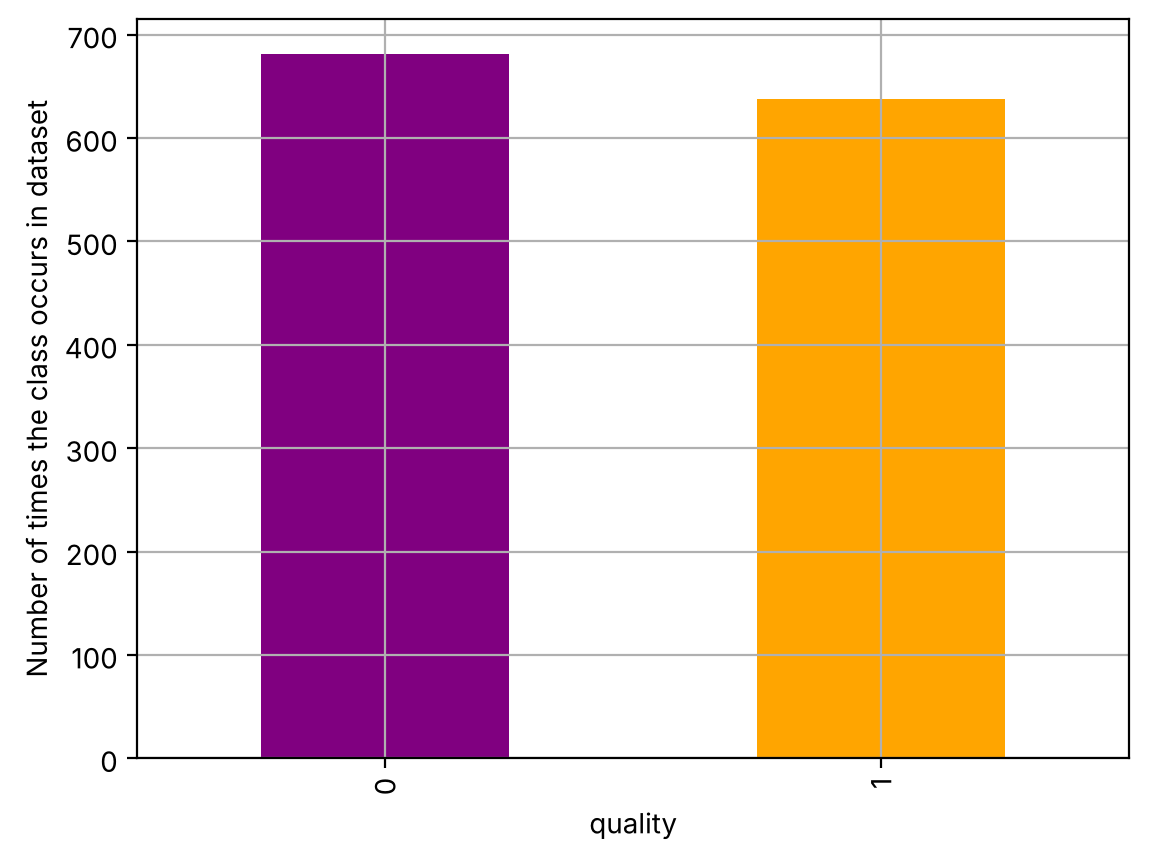

In [16]:
y.value_counts().plot.bar(color=['purple', 'orange'], grid=True)
plt.ylabel('Number of times the class occurs in dataset');

It all depends on the base rate. Base rate = $\frac{\text{number of observations in the most frequent class}}{\text{total number of observations}}$

The base rate (or accuracy of the naive classifier) is the accuracy you would get by always predicting the majority class.

If the base rate is very high, the dataset is imbalanced: one class has many more observations than the others, and a high accuracy is easy to reach without learning anything.

Let's compute the base rate!

In [17]:
#Compute the base rate
#Base rate = (# occurrences of the most frequent class)/(# total observations)

quality_0 = wines.loc[wines["quality"] == 0].shape[0]
print("# occurrences of class 0 ", quality_0)
quality_1 = wines.loc[wines["quality"] == 1].shape[0]
print("# occurrences of class 1 ", quality_1)
print("Baserate = ", max(quality_0, quality_1)/(wines["quality"].shape[0]))

# occurrences of class 0  681
# occurrences of class 1  638
Baserate =  0.5163002274450341


The base rate is about 52%: one class is slightly more frequent than the other, but the dataset is fairly balanced.

The model reaches an accuracy of about 71%, roughly 19 percentage points above the base rate. The model has therefore learned patterns beyond simply guessing the majority class.

#### Confusion matrix
The confusion matrix gives more detail on the performance of the model. It shows what the model gets right and which types of errors it makes.

It has this form:

|   | Class 0 predicted  | Class 1 predicted  |    
|---|---|---|
| **Class 0 actual**  |  TN |FP   |    
| **Class 1 actual**  | FN  | TP  |   

<br>

where TP = true positives, FN = false negatives, FP = false positives and TN = true negatives. Here class 1 is the "positive" class.

In [18]:
pd.Series(y_pred).value_counts()

0    214
1    182
Name: count, dtype: int64

These are the numbers of test samples that the model predicts in class 0 and in class 1.

In [19]:
y_test.value_counts()

quality
0    211
1    185
Name: count, dtype: int64

And these are the numbers of test samples that are really in each class.   
But how many of the class 0 predictions are actual class 0 samples?

In [20]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_pred)


array([[155,  56],
       [ 59, 126]])

We can also display the confusion matrix with seaborn.

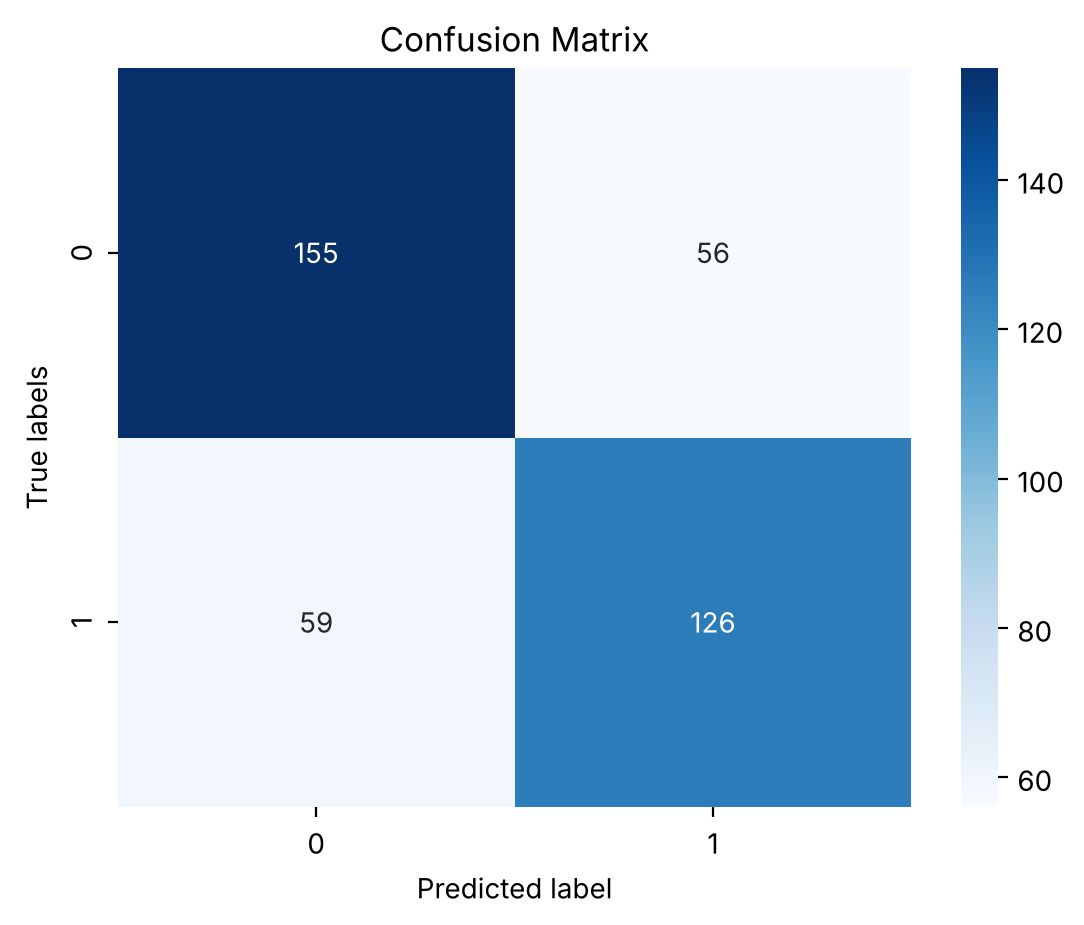

In [21]:
sns.heatmap(pd.DataFrame(confusion_matrix(y_test, y_pred)), annot=True, cmap='Blues', fmt='.4g')
plt.xlabel('Predicted label')
plt.ylabel('True labels')
plt.title('Confusion Matrix');

**Accuracy**: the fraction of correct predictions among all predictions.

Let's check the accuracy of this model again. We can compute it by hand or with functions of scikit-learn.

In [22]:
model.score(X_test, y_test)

0.7095959595959596

In [23]:
# or with the accuracy_score function imported previously from sklearn metrics
accuracy_score(y_test, y_pred)

0.7095959595959596

With the confusion matrix, you can compute the accuracy by hand:
$$
\text{Accuracy} = \frac{TN + TP}{TN + TP + FP + FN}
$$

In [24]:
# or also by hand, from the confusion matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
(tn + tp) / (tn + tp + fp + fn)

np.float64(0.7095959595959596)

#### Optional: precision (you can skip this)

Precision is another useful score for a fuller picture of the performance of the model.   
**Precision:** how often the model is correct when it predicts the positive class (1). Precision = TP/(TP+FP)


In [25]:
from sklearn.metrics import precision_score
precision_score(y_test, y_pred)

0.6923076923076923

In [26]:
# precision for class 1 computed by hand
tp / (tp + fp)

np.float64(0.6923076923076923)

In [27]:
# precision score for both classes 0 and 1
precision_score(y_test, y_pred, average=None)

array([0.72429907, 0.69230769])

#### 6) Visualization of the model: decision boundary

To visualize the model, let's build a 2D model that predicts the quality from the alcohol and sulphates content, and plot its decision boundary. The boundary splits the plane into zones, one for each class: a point is assigned to a class depending on the side of the boundary it falls on.

Here the data has 2 dimensions and the model is a binary classifier (2 classes).

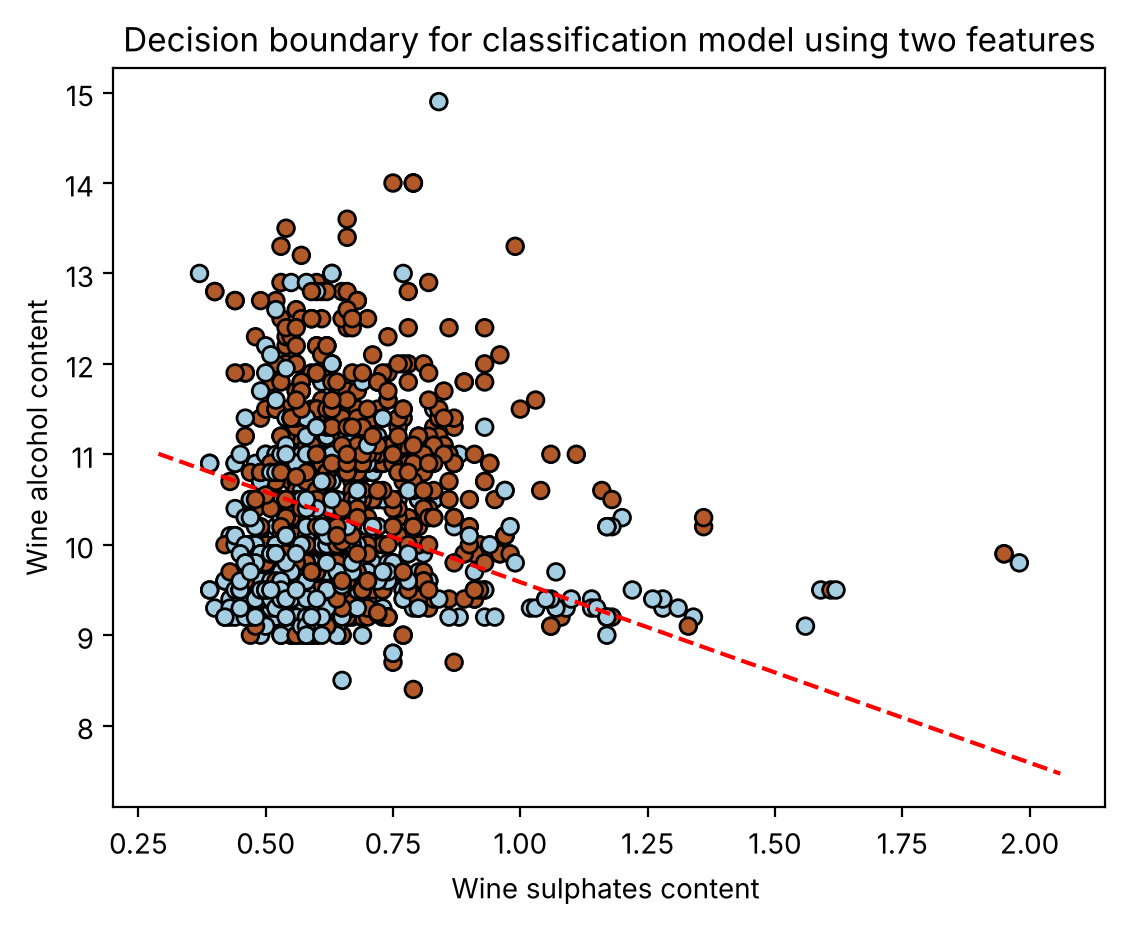

In [28]:
#Decision boundaries
import numpy as np
import matplotlib.pyplot as plt


X = X [['sulphates', 'alcohol']]
model = LogisticRegression()
model.fit(X, y)


plt.scatter(X['sulphates'].values, X['alcohol'].values, c=y, edgecolors='k', cmap=plt.cm.Paired)
ax = plt.gca()
x_vals = np.array(ax.get_xlim())
y_vals = (-x_vals * model.coef_[0][0] - model.intercept_[0])/model.coef_[0][1]
plt.plot(x_vals, y_vals, '--', c="red")

plt.xlabel('Wine sulphates content ')
plt.ylabel('Wine alcohol content')
plt.title('Decision boundary for classification model using two features')

plt.show()

In [29]:
model.intercept_

array([-10.58982574])

In [30]:
model.coef_

array([[1.82554455, 0.91418715]])

Let's interpret this chart. The red dotted line is the boundary between the two regions. Everything on one side of the line is assigned to one class, and everything on the other side to the other class.
The closer a point is to the boundary, the less certain the classification. The line is computed from the coefficients of the model.

#### 7) How the model classifies new data points

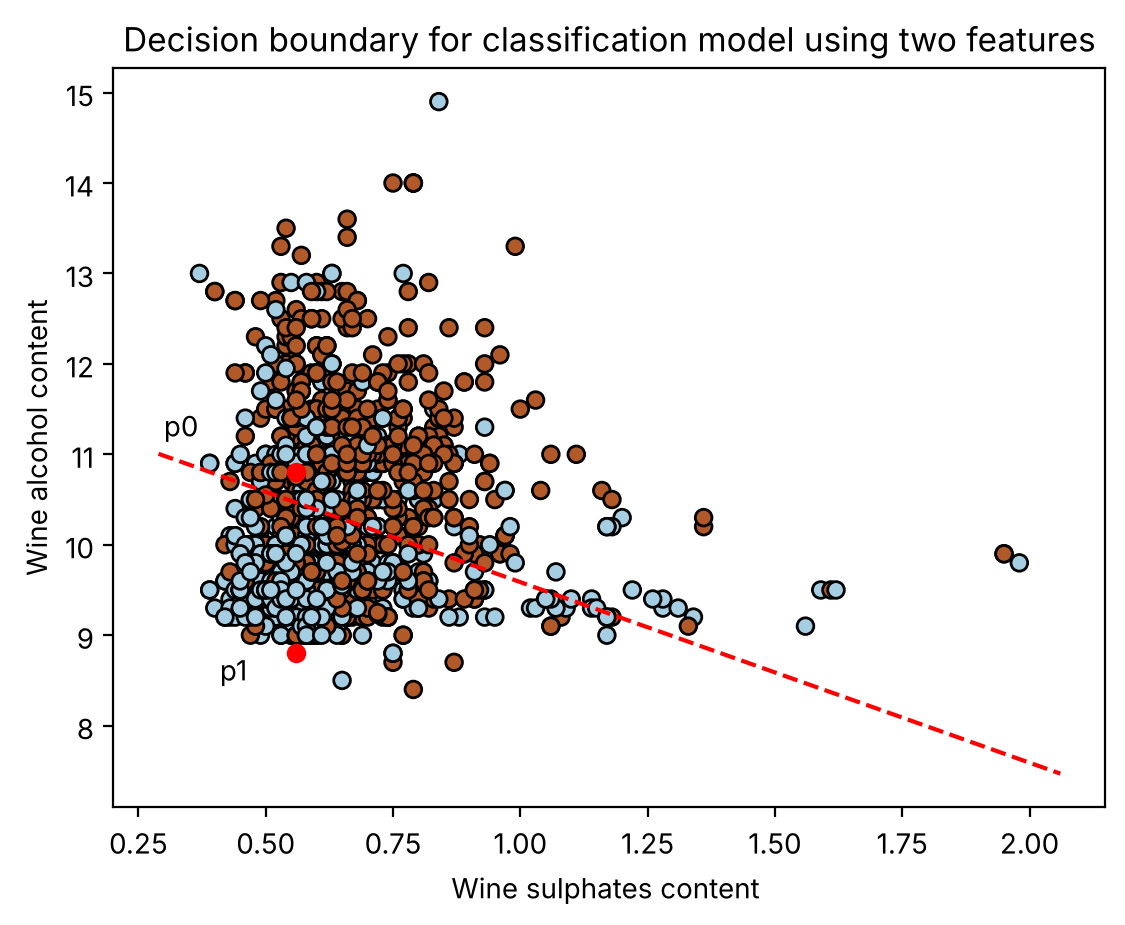

In [31]:
X = X [['sulphates', 'alcohol']]
model = LogisticRegression()
model.fit(X, y)


plt.scatter(X['sulphates'].values, X['alcohol'].values, c=y, edgecolors='k', cmap=plt.cm.Paired)
ax = plt.gca()
x_vals = np.array(ax.get_xlim())
y_vals = (-x_vals * model.coef_[0][0] - model.intercept_[0])/model.coef_[0][1]
plt.plot(x_vals, y_vals, '--', c="red")

plt.xlabel('Wine sulphates content ')
plt.ylabel('Wine alcohol content')
plt.title('Decision boundary for classification model using two features')

#two new unseen points
plt.scatter(0.56, 10.8, c='red') # p0
plt.scatter(0.56, 8.8, c='red') #p1
plt.text(0.3, 11.2, 'p0') # the label of p0
plt.text(0.41, 8.5, 'p1') # the label of p1

plt.show()

In [32]:
x_new=pd.DataFrame([[0.56,10.8], [0.56,8.8]], columns=['sulphates', 'alcohol'])
x_new

,sulphates,alcohol
0,0.56,10.8
1,0.56,8.8


In [33]:
model.predict(x_new)

array([1, 0])

As expected, a wine with sulphates at 0.56 and 8.8% alcohol is in one class, while a wine with the same sulphates and 10.8% alcohol is in the other class.

We can also compute the probability of each class. A point on the boundary has equal probability for both classes.

In [34]:
model.predict_proba(x_new)

array([[0.42416457, 0.57583543],
       [0.82093189, 0.17906811]])

The second data point is classified with almost complete certainty, which makes sense since it is far from the boundary. The first one is much more uncertain.

#### 8) Adding cross-validation
We now use logistic regression with cross-validation: instead of `LogisticRegression()` we use `LogisticRegressionCV(cv=K)`.

Cross-validation helps to prevent overfitting. As before, we split the data into train and test sets, fit the model on the training data and evaluate it on the test data. **The difference** is that the model now repeats the fitting K times on different parts of the training data, and uses the average error to choose its regularization strength.

In [35]:
#Create model
from sklearn.linear_model import LogisticRegressionCV
model_cv = LogisticRegressionCV(solver='lbfgs', cv=5, max_iter=1000)

In [36]:
#Fit the model using the training data
model_cv.fit(X_train, y_train)

,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"max_iter max_iter: int, default=100Maximum number of iterations of the optimization algorithm.",1000
,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.",'warn'
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'warn'
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblin

In [37]:
#Use model on test and check accuracy
print('Accuracy of Logistic regression classifier on test set: {:.2f}'
     .format(model_cv.score(X_test, y_test)))

# also possible to calculate on the test set
print('Accuracy of Logistic regression classifier on training set: {:.2f}'
     .format(model_cv.score(X_train, y_train)))

Accuracy of Logistic regression classifier on test set: 0.71
Accuracy of Logistic regression classifier on training set: 0.71


In [38]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
cf = confusion_matrix(y_test, model_cv.predict(X_test))
print(cf)

[[150  61]
 [ 55 130]]


Let's make the confusion matrix a little nicer.

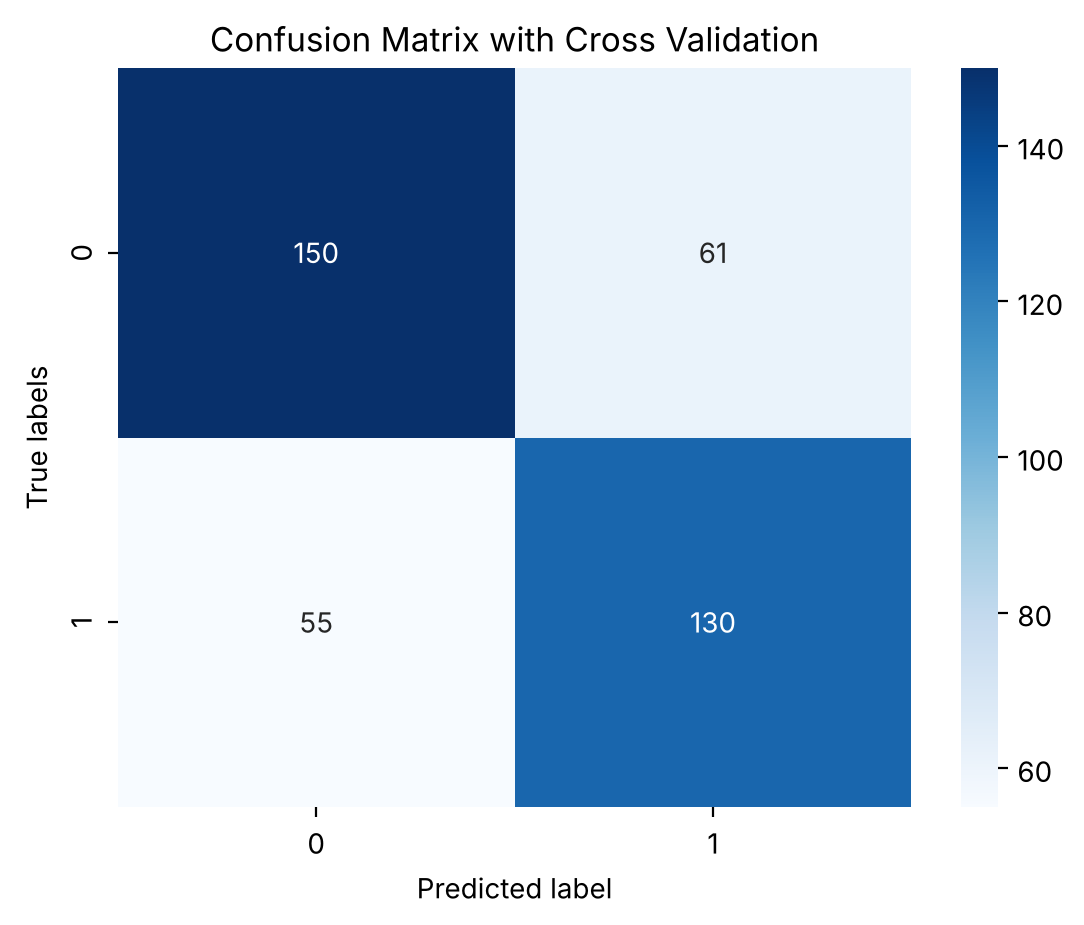

In [39]:
sns.heatmap(pd.DataFrame(confusion_matrix(y_test, model_cv.predict(X_test))), annot=True, cmap='Blues', fmt='.4g')
plt.xlabel('Predicted label')
plt.ylabel('True labels')
plt.title('Confusion Matrix with Cross Validation');

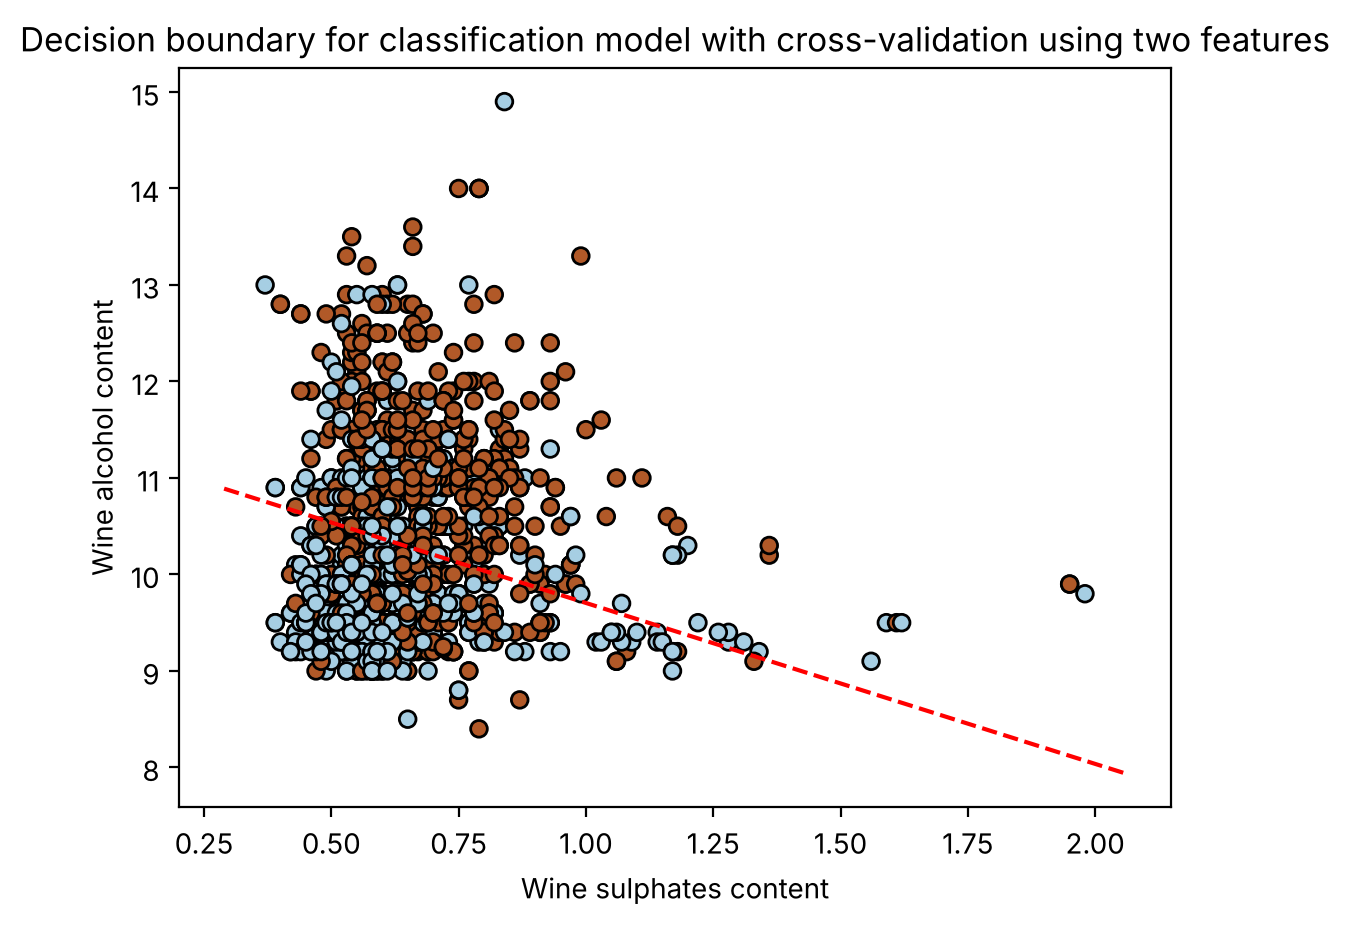

In [40]:
#Decision boundary
import numpy as np
import matplotlib.pyplot as plt


X = X [['sulphates', 'alcohol']]
model = LogisticRegressionCV(solver='lbfgs', cv=5, max_iter=1000)
model.fit(X, y)


plt.scatter(X['sulphates'].values, X['alcohol'].values, c=y, edgecolors='k', cmap=plt.cm.Paired)
ax = plt.gca()
x_vals = np.array(ax.get_xlim())
y_vals = (-x_vals * model.coef_[0][0] - model.intercept_[0])/model.coef_[0][1]
plt.plot(x_vals, y_vals, '--', c="red")

plt.xlabel('Wine sulphates content')
plt.ylabel('Wine alcohol content')


plt.title('Decision boundary for classification model with cross-validation using two features')

plt.show()